In [1]:
import os
import copy
import keras
import math
import glob
import random
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
import tensorflow as tf
from keras.layers import *
from keras.optimizers import *
from keras import backend as K
from keras.models import Model
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from collections import defaultdict
from sklearn.model_selection import KFold, StratifiedKFold
from scipy.spatial.distance import cdist
import scipy.ndimage.interpolation as inter
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.callbacks import TensorBoard
from sklearn.metrics import roc_curve, auc, accuracy_score, confusion_matrix

2025-03-25 18:41:44.861617: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-25 18:41:44.873809: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1742946104.885613   97545 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1742946104.889423   97545 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-25 18:41:44.903966: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
random.seed(1234)

class Config():
    def __init__(self):
        self.frame_l = 64 # the length of frames
        self.joint_n = 33 # the number of joints
        self.joint_d = 3 # the dimension of joints
        self.clc = 3 # the number of coarse class
        self.feat_d = 528
        self.filters = 64
        self.num_folds = 5
        self.data_dir = r'/home/nyam/Ms_Thesis/Autism/Project_v3/DataProcessing/aug_skel'
        self.dataset_info = r"/home/nyam/Ms_Thesis/Autism/Project_v3/DataProcessing/aug_dataset_info.txt"
C = Config()

In [3]:
#Rescale to be 64 frames
def zoom(p,target_l=64,joints_num=33,joints_dim=3):
    l = p.shape[0]
    p_new = np.empty([target_l,joints_num,joints_dim])
    for m in range(joints_num):
        for n in range(joints_dim):
            p[:,m,n] = medfilt(p[:,m,n],3)
            p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
    return p_new


def get_CG(p,C):
    M = []
    iu = np.triu_indices(C.joint_n,1,C.joint_n)
    for f in range(C.frame_l):
        #distance max
        d_m = cdist(p[f],np.concatenate([p[f],np.zeros([1,C.joint_d])]),'euclidean')
        d_m = d_m[iu]
        M.append(d_m)
    M = np.stack(M)
    return M

def normlize_range(p):
    # normolize to start point, use the center for hand case
    p[:,:,0] = p[:,:,0]-np.mean(p[:,:,0])
    p[:,:,1] = p[:,:,1]-np.mean(p[:,:,1])
    p[:,:,2] = p[:,:,2]-np.mean(p[:,:,2])
    return p

# Function to read dataset info from file
def read_dataset_info(file_path):
    dataset_info = []
    with open(file_path, "r") as info_file:
        for line in info_file:
            # Strip any leading or trailing whitespace and split the line by tabs
            info = line.strip().split("\t")
            if info[1] != "HandAction":
                dataset_info.append(info)
    return dataset_info

# Function to perform label encoding
def label_encode(dataset_info):
    label_encoder = LabelEncoder()
    labels = [info[1] for info in dataset_info]
    #print(dataset_info)
    encoded_labels = label_encoder.fit_transform(labels)

    for i, info in enumerate(dataset_info):
        dataset_info[i] = list(info)  # Convert tuple to list
        dataset_info[i][1] = encoded_labels[i]  # Modify the label
    
    return dataset_info


In [4]:

def poses_diff(x):
    H, W = x.get_shape()[1],x.get_shape()[2]
    x = tf.subtract(x[:,1:,...],x[:,:-1,...])
    x = tf.image.resize(x,size=[H,W])
    return x

def pose_motion(P,frame_l):
    P_diff_slow = Lambda(lambda x: poses_diff(x))(P)
    P_diff_slow = Reshape((frame_l,-1))(P_diff_slow)
    
    P_fast = Lambda(lambda x: x[:,::2,...])(P)
    P_diff_fast = Lambda(lambda x: poses_diff(x))(P_fast)
    P_diff_fast = Reshape((int(frame_l/2),-1))(P_diff_fast)
    return P_diff_slow,P_diff_fast

def c1D(x,filters,kernel):
    x = Conv1D(filters, kernel_size=kernel,padding='same',use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.2)(x)
    return x

def block(x,filters):
    x = c1D(x,filters,3)
    x = c1D(x,filters,3)
    return x

def d1D(x,filters):
    x = Dense(filters,use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.2)(x)
    return x

def build_FM(frame_l=90,joint_n=33,joint_d=2,feat_d=528,filters=64):
    M = Input(shape=(frame_l,feat_d))
    P = Input(shape=(frame_l,joint_n,joint_d))

    diff_slow,diff_fast = pose_motion(P,frame_l)

    x = c1D(M,filters*2,1)
    x = SpatialDropout1D(0.1)(x)
    x = c1D(x,filters,3)
    x = SpatialDropout1D(0.1)(x)
    x = c1D(x,filters,1)
    x = MaxPooling1D(2)(x)
    x = SpatialDropout1D(0.1)(x)

    x_d_slow = c1D(diff_slow,filters*2,1)
    x_d_slow = SpatialDropout1D(0.1)(x_d_slow)
    x_d_slow = c1D(x_d_slow,filters,3)
    x_d_slow = SpatialDropout1D(0.1)(x_d_slow)
    x_d_slow = c1D(x_d_slow,filters,1)
    x_d_slow = MaxPool1D(2)(x_d_slow)
    x_d_slow = SpatialDropout1D(0.1)(x_d_slow)

    x_d_fast = c1D(diff_fast,filters*2,1)
    x_d_fast = SpatialDropout1D(0.1)(x_d_fast)
    x_d_fast = c1D(x_d_fast,filters,3)
    x_d_fast = SpatialDropout1D(0.1)(x_d_fast)
    x_d_fast = c1D(x_d_fast,filters,1)
    x_d_fast = SpatialDropout1D(0.1)(x_d_fast)

    x = concatenate([x,x_d_slow,x_d_fast])
    
    x = block(x,filters*2) #convolution
    x = MaxPool1D(2)(x)
    x = SpatialDropout1D(0.1)(x)

    x = block(x,filters*4)
    x = MaxPool1D(2)(x)
    x = SpatialDropout1D(0.1)(x)

    x = block(x,filters*8)
    x = SpatialDropout1D(0.1)(x)
    
    
    return Model(inputs=[M,P],outputs=x)


def build_stim_Net(frame_l=90,joint_n=33,joint_d=3,feat_d=231,clc_num=14,filters=16):
    M = Input(name='M', shape=(frame_l,feat_d))
    P = Input(name='P', shape=(frame_l,joint_n,joint_d))

    FM = build_FM(frame_l,joint_n,joint_d,feat_d,filters)

    x = FM([M,P])

    x = GlobalMaxPool1D()(x)

    x = d1D(x,254)
    x = Dropout(0.5)(x)
    x = d1D(x,128)
    x = Dropout(0.5)(x)
    x = d1D(x,64)
    x = Dropout(0.5)(x)
    x = d1D(x,32)
    x = Dropout(0.5)(x)
    x = Dense(clc_num, activation='softmax')(x)
    
    model = Model(inputs=[M,P],outputs=x)
    return model

In [5]:
stim_Net = build_stim_Net(C.frame_l,C.joint_n,C.joint_d,C.feat_d,C.clc,C.filters)
lr = 1e-3
stim_Net.compile(loss="categorical_crossentropy",optimizer=keras.optimizers.Adam(lr),metrics=['accuracy'])
lrScheduler = keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.1, patience=10, cooldown=5, min_lr=1e-6)
stim_Net.summary()

I0000 00:00:1742946107.520637   97545 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3620 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ M (InputLayer)      │ (None, 64, 528)   │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ P (InputLayer)      │ (None, 64, 33, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 8, 512)    │  1,786,624 │ M[0][0], P[0][0]  │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 512)       │          0 │ functional[0][0]  │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 254)       │    130,048 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 254)       │      1,016 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_15      │ (None, 254)       │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 254)       │          0 │ leaky_re_lu_15[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_16      │ (None, 128)       │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ leaky_re_lu_16[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,192 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_17      │ (None, 64)        │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ leaky_re_lu_17[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,048 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_18      │ (None, 32)        │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ leaky_re_lu_18[0

 Total params: 1,961,435 (7.48 MB)

 Trainable params: 1,955,359 (7.46 MB)

 Non-trainable params: 6,076 (23.73 KB)

In [6]:
# --- Visualization: Confusion Matrix ---
def plot_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [7]:
def data_loader(dataset):
    data = {}
    data['pose'] = []
    data['label'] = []
    
    for i in tqdm(range(len(dataset))):
        label = dataset[i][1]
        skeletons = dataset[i][0]
        
        skeleton_path =os.path.join(C.data_dir, str(skeletons))
        
        try:
            p = np.load(skeleton_path).astype('float32')
            for j in range(p.shape[1]):
                p[:, j] = medfilt(p[:, j])
            
            data['pose'].append(p)
            data['label'].append(label)
        except Exception as e:
            print(f"An error occurred while processing {skeletons}: {e}")
            
    X_0 = []
    X_1 = []
    Y = []
    
    for i in tqdm(range(len(data['pose']))):
        p = np.copy(data['pose'][i]).reshape([-1,33,3])
        if(p.shape[0]>10):
            p = zoom(p,target_l=C.frame_l,joints_num=C.joint_n,joints_dim=C.joint_d)
            p = normlize_range(p)
            # print(p)
            label = np.zeros(C.clc)
            #print(int(Train['label'][i]))
            label[int(data['label'][i])] = 1
    
            M = get_CG(p,C)
    
            X_0.append(M)
            X_1.append(p)
            Y.append(label)
    
    return np.stack(X_0) , np.stack(X_1), np.stack(Y)

In [8]:

# Define the path to the dataset info file
output_info_file = C.dataset_info  # Path to dataset info

# Load dataset info
dataset_info = read_dataset_info(output_info_file)

# Group subjects per class
classwise_subjects = defaultdict(lambda: defaultdict(list))
labels = []

for info in dataset_info:
    class_label = info[1]  # Class (e.g., "Spinning", "HeadBanging")
    filename = info[2]     # Extract filename
    parts = filename.split('_')
    subject_id = f"{parts[1]}_{parts[2]}"  # Unique subject identifier
    
    classwise_subjects[class_label][subject_id].append((filename, class_label))  # Store filename & label

subject_to_label = {}

# Iterate over classwise_subjects to populate subject labels
for class_label, subjects in classwise_subjects.items():
    for subject_id in subjects.keys():
        subject_to_label[subject_id] = class_label  # Assign class label to subject

# Collect unique subjects across all classes
all_subjects = list(subject_to_label.keys())  # Unique subjects
labels = [subject_to_label[subj] for subj in all_subjects]  # List of class labels

# Perform balanced train-test split for each class
random.seed(42)  # Ensure reproducibility
random.shuffle(all_subjects)

# Create subject-level KFold splits
kfold = StratifiedKFold(n_splits=C.num_folds, shuffle=True)  # No shuffle since manually shuffled

fold_results = []

y_true_pred = []

for fold, (train_subj_idx, test_subj_idx) in enumerate(kfold.split(all_subjects, labels)):
    print(f"\n--- Fold {fold+1}/{C.num_folds} ---")

    # train_subjects = set([all_subjects[i] for i in np.concatenate((train_subj_idx, test_subj_idx[:4]))])
    # test_subjects = set([all_subjects[i] for i in np.concatenate((test_subj_idx, train_subj_idx[:4]))])

    train_subjects = set([all_subjects[i] for i in train_subj_idx])
    test_subjects = set([all_subjects[i] for i in test_subj_idx])


    # Create train and test sets ensuring mutual exclusivity
    train_list = label_encode([vid for class_subjects in classwise_subjects.values() 
                  for subj, vids in class_subjects.items() if subj in train_subjects for vid in vids])
    test_list = label_encode([vid for class_subjects in classwise_subjects.values() 
                 for subj, vids in class_subjects.items() if subj in test_subjects for vid in vids])

    # print(train_subjects)
    # print("------------------------------------")
    # print(test_subjects)

    x_0,x_1,y = data_loader(train_list)
    xt_0, xt_1,yt = data_loader(test_list)
    
    stim_Net = build_stim_Net(C.frame_l,C.joint_n,C.joint_d,C.feat_d,C.clc,C.filters)
    lr = 1e-3
    stim_Net.compile(loss="categorical_crossentropy",optimizer=keras.optimizers.Adam(lr),metrics=['accuracy'])
    lrScheduler = keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.1, patience=5, cooldown=3, min_lr=1e-3)
    
    history = stim_Net.fit([x_0,x_1],y,
            batch_size=64,
            epochs=300,
            verbose=True,
            shuffle=True,
            callbacks=[lrScheduler],
            validation_data=([xt_0, xt_1],yt)
            )

    Y_pred = stim_Net.predict([xt_0, xt_1])
    labels = ['Arm Flapping', 'HeadBanging', 'Spinning']
    
    y_true = []
    for i in np.argmax(yt,axis=1):
        y_true.append(labels[i])
    
    y_pred = []
    for i in np.argmax(Y_pred,axis=1):
        y_pred.append(labels[i])
        
    # plot_confusion_matrix(y_true, y_pred, labels)
    
    y_true_pred.append([y_true, y_pred, labels])
    
    accuracy = accuracy_score(y_true,y_pred)
    print("Accuracy:", accuracy)

    fold_results.append(accuracy)

# Print final results
avg_accuracy = np.mean(fold_results)
print(f"\nFinal Cross-Validation Accuracy: {avg_accuracy:.4f}")

print(fold_results)



--- Fold 1/5 ---


  0%|                                                                                                                               | 0/356 [00:00<?, ?it/s]/tmp/ipykernel_97545/143893866.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 91/91 [00:00<00:00, 187.09it/s]
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Epoch 1/300


/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/models/functional.py:225: UserWarning: The structure of `inputs` doesn't match the expected structure: ['M', 'P']. Received: the structure of inputs=('*', '*')
  warnings.warn(
I0000 00:00:1742946117.683926   97626 service.cc:148] XLA service 0x7fdccc003cf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1742946117.683977   97626 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2025-03-25 18:41:57.807780: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1742946118.375613   97626 cuda_dnn.cc:529] Loaded cuDNN version 90501
I0000 00:00:1742946127.781463   97626 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


6/6 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.3439 - loss: 1.5210 - val_accuracy: 0.3667 - val_loss: 1.0967 - learning_rate: 0.0010
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3878 - loss: 1.2886 - val_accuracy: 0.3111 - val_loss: 1.1046 - learning_rate: 0.0010
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4623 - loss: 1.1959 - val_accuracy: 0.3222 - val_loss: 1.1296 - learning_rate: 0.0010
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 275ms/step - accuracy: 0.4166 - loss: 1.2082 - val_accuracy: 0.3333 - val_loss: 1.1425 - learning_rate: 0.0010
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4042 - loss: 1.2429 - val_accuracy: 0.3667 - val_loss: 1.1687 - learning_rate: 0.0010
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4622 - loss: 1.1070 - val_accuracy: 0.4111 - val_loss: 1.1464 - learning_rate: 0.0010
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5131 - loss: 1.0561 - val_accuracy: 0.4444 - val

  0%|                                                                                                                               | 0/356 [00:00<?, ?it/s]/tmp/ipykernel_97545/143893866.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 91/91 [00:00<00:00, 186.85it/s]
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


... (13 outputs left out)

  0%|                                                                                                                               | 0/361 [00:00<?, ?it/s]/tmp/ipykernel_97545/143893866.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 86/86 [00:00<00:00, 185.87it/s]
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Epoch 1/300


/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/models/functional.py:225: UserWarning: The structure of `inputs` doesn't match the expected structure: ['M', 'P']. Received: the structure of inputs=('*', '*')
  warnings.warn(


6/6 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.2637 - loss: 1.7935 - val_accuracy: 0.5488 - val_loss: 1.0542 - learning_rate: 0.0010
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3819 - loss: 1.3762 - val_accuracy: 0.5488 - val_loss: 1.0558 - learning_rate: 0.0010
Epoch 3/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3424 - loss: 1.3607 - val_accuracy: 0.5488 - val_loss: 1.1362 - learning_rate: 0.0010
Epoch 4/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3649 - loss: 1.3012 - val_accuracy: 0.5488 - val_loss: 1.1909 - learning_rate: 0.0010
Epoch 5/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4252 - loss: 1.1191 - val_accuracy: 0.5732 - val_loss: 1.3319 - learning_rate: 0.0010
Epoch 6/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5138 - loss: 1.1066 - val_accuracy: 0.5610 - val_loss: 1.4389 - learning_rate: 0.0010
Epoch 7/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4664 - loss: 1.0651 - val_accuracy: 0.5244 - val_


--- Fold 1 Evaluation ---


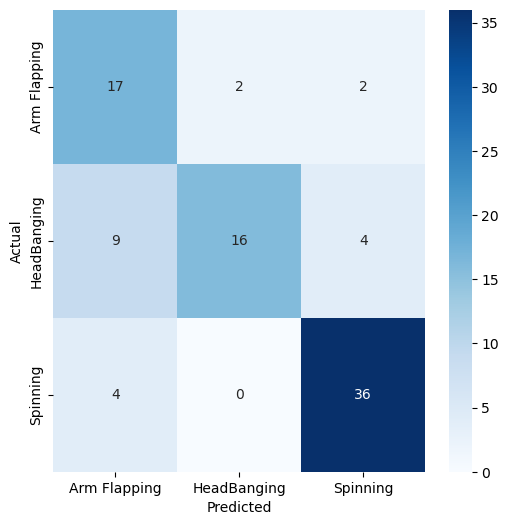

Accuracy: 0.7667
Weighted Accuracy: 0.7667
Precision: 0.7709
Recall: 0.7537
Weighted F1-score: 0.7652
AUC: nan
IoC: 0.2333

--- Fold 2 Evaluation ---


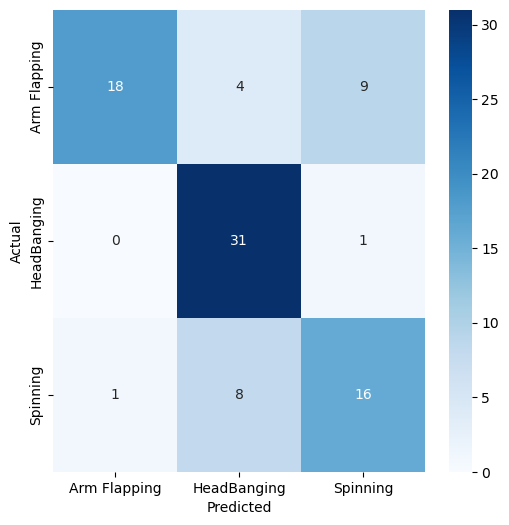

Accuracy: 0.7386
Weighted Accuracy: 0.7386
Precision: 0.7612
Recall: 0.7298
Weighted F1-score: 0.7325
AUC: nan
IoC: 0.2614

--- Fold 3 Evaluation ---


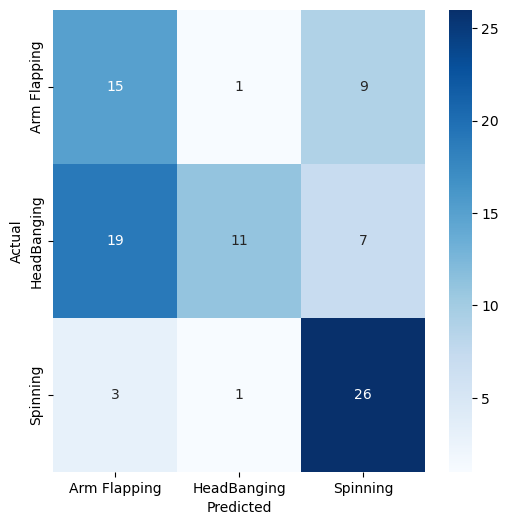

Accuracy: 0.5652
Weighted Accuracy: 0.5652
Precision: 0.6235
Recall: 0.5880
Weighted F1-score: 0.5440
AUC: nan
IoC: 0.4348

--- Fold 4 Evaluation ---


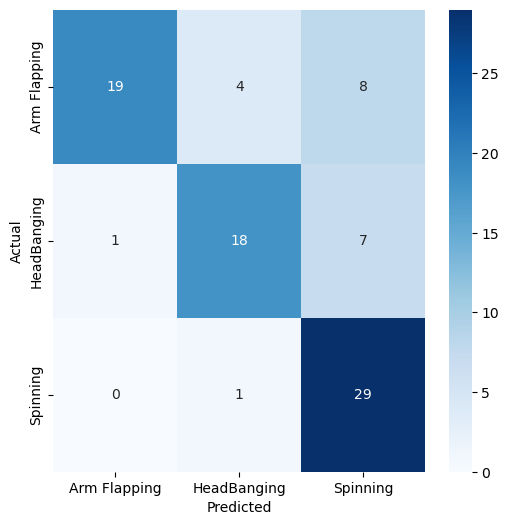

Accuracy: 0.7586
Weighted Accuracy: 0.7586
Precision: 0.7972
Recall: 0.7573
Weighted F1-score: 0.7553
AUC: nan
IoC: 0.2414

--- Fold 5 Evaluation ---


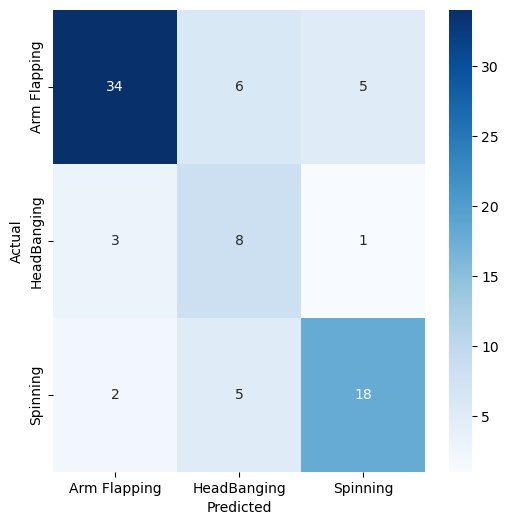

Accuracy: 0.7317
Weighted Accuracy: 0.7317
Precision: 0.6809
Recall: 0.7141
Weighted F1-score: 0.7438
AUC: nan
IoC: 0.2683

--- Final Cross-Validation Results ---
Accuracy: Mean = 0.7122, Std = 0.0746
Weighted Accuracy: 0.7122
Precision: 0.7268
Recall: 0.7086
Weighted F1-score: 0.7081
AUC: nan
IoC: 0.2878


/tmp/ipykernel_97545/4080142418.py:70: RuntimeWarning: Mean of empty slice
  mean_auc = np.nanmean(auc_scores)  # Ignore NaN values


In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Initialize lists to store evaluation metrics per fold
conf_matrices = []
accuracies = []
weighted_accuracies = []
precisions = []
recalls = []
weighted_f1_scores = []
auc_scores = []
ioc_scores = []

# Iterate over each fold's results
for fold, data in enumerate(y_true_pred):
    y_true, y_pred, labels = data  # Extract values

    print(f"\n--- Fold {fold+1} Evaluation ---")

     # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    conf_matrices.append(cm)

    # Compute confusion matrix
    plot_confusion_matrix(y_true, y_pred, labels=labels)

    

    # Compute accuracy
    acc = accuracy_score(y_true, y_pred)
    weighted_acc = np.sum(np.diag(cm)) / np.sum(cm)  # Alternative weighted accuracy
    accuracies.append(acc)
    weighted_accuracies.append(weighted_acc)

    # Compute precision, recall, and weighted F1-score
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')

    precisions.append(precision)
    recalls.append(recall)
    weighted_f1_scores.append(weighted_f1)

    # Compute AUC (One-vs-Rest method)
    try:
        auc = roc_auc_score(y_true, y_pred, average='macro', multi_class="ovr")
    except ValueError:
        auc = float('nan')  # Handle cases where AUC calculation is not possible
    auc_scores.append(auc)

    # Compute IoC (Index of Confusion) as 1 - accuracy
    ioc = 1 - acc
    ioc_scores.append(ioc)

    # Print results for the fold
    print(f"Accuracy: {acc:.4f}")
    print(f"Weighted Accuracy: {weighted_acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Weighted F1-score: {weighted_f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"IoC: {ioc:.4f}")

# Compute mean and std for all metrics across folds
mean_acc = np.mean(accuracies)
std_acc = np.std(accuracies)
mean_weighted_acc = np.mean(weighted_accuracies)
mean_precision = np.mean(precisions)
mean_recall = np.mean(recalls)
mean_weighted_f1 = np.mean(weighted_f1_scores)
mean_auc = np.nanmean(auc_scores)  # Ignore NaN values
mean_ioc = np.mean(ioc_scores)

# Print overall results
print("\n--- Final Cross-Validation Results ---")
print(f"Accuracy: Mean = {mean_acc:.4f}, Std = {std_acc:.4f}")
print(f"Weighted Accuracy: {mean_weighted_acc:.4f}")
print(f"Precision: {mean_precision:.4f}")
print(f"Recall: {mean_recall:.4f}")
print(f"Weighted F1-score: {mean_weighted_f1:.4f}")
print(f"AUC: {mean_auc:.4f}")
print(f"IoC: {mean_ioc:.4f}")
